# Is Rare Whiskey Actually a Good Investment?
**The idea:** Working at a whiskey bar, you hear that rare bottles are "better than stocks," and some sell for thousands at auction. This project tests that claim with real auction data and compares it to the S&P 500.

**Data**
- [DramValue Whisky Prices](https://huggingface.co/datasets/datamatters24/dramvalue-whisky-prices) (public domain): ~30,000 bottles and 1.35 million real auction and retail sale prices
- [S&P 500 monthly index levels](https://github.com/datasets/s-and-p-500) for the comparison

**Tools:** SQL (DuckDB) and Python (pandas, matplotlib) in Google Colab

**Steps**
1. Explore the bottles
2. Which types of whiskey are worth the most?
3. Does older whiskey sell for more?
4. How has the auction market grown?
5. Whiskey vs. the stock market
6. Conclusion

## Setup
Downloads the data and loads it into DuckDB, a SQL database that runs inside Python. `q()` is a helper: give it a SQL query as text and it returns the result as a table (like a Java method that takes a String and returns a result).

In [1]:
import os, urllib.request
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

BASE = "https://huggingface.co/datasets/datamatters24/dramvalue-whisky-prices/resolve/main/"
os.makedirs("data", exist_ok=True)
for f in ["dramvalue_bottles.csv", "dramvalue_prices.csv"]:          # prices file is ~330 MB, takes a minute
    if not os.path.exists(f"data/{f}"):
        urllib.request.urlretrieve(BASE + f, f"data/{f}")

con = duckdb.connect("data/whiskey.duckdb")
con.sql("CREATE OR REPLACE TABLE bottles AS SELECT * FROM 'data/dramvalue_bottles.csv'")
con.sql("""CREATE OR REPLACE TABLE prices AS
           SELECT price_id, bottle_id, price_usd, source, transaction_date
           FROM 'data/dramvalue_prices.csv'""")
con.sql("""CREATE OR REPLACE TABLE sp500 AS
           SELECT * FROM read_csv_auto('https://raw.githubusercontent.com/datasets/s-and-p-500/main/data/data.csv')""")

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

# chart style
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe8",
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left"})

q("SELECT 'bottles' AS tbl, COUNT(*) AS rows FROM bottles UNION ALL SELECT 'prices', COUNT(*) FROM prices")

,tbl,rows
0,bottles,30324
1,prices,1351454


## Step 1: Explore the bottles
First, look at what's in the data and check its quality.

**How it works:** `SELECT` picks columns, `FROM` picks the table, `WHERE` filters rows, `ORDER BY ... DESC` sorts biggest first, and `LIMIT` keeps the top rows. `price_count` is how many sales an average is based on.

In [2]:
q("""
SELECT name, avg_price, price_count
FROM bottles
WHERE category = 'BOURBON'
ORDER BY avg_price DESC
LIMIT 10
""")

,name,avg_price,price_count
0,Heaven Hill Bernheim (Barrel) Cask,9251.490000,3
1,Heaven Hill 11 Year Old (Barrel) Cask,7664.840000,1
2,Old Rip Van Winkle,5903.843712,10711
3,Very Very Old Fitzgerald,2054.596774,868
4,King of Kentucky,1479.423868,8991
5,Black Maple Hill,1362.525397,6418
6,William Larue Weller,1297.501883,44074
7,Vintage Bourbon,1293.437519,3225
8,Eagle Rare,1204.241811,7663
9,Woodford Reserve,1103.503952,2657


**Data quality check:** the top two "bottles" are whole barrels sold only 1–3 times, so one sale sets the average. To avoid that, the rest of the analysis only uses bottles with enough sales.

Also, plain "Buffalo Trace" averages ~$647 even though it's a ~$30 shelf bottle. Some listings lump in rare auction releases, so **this data describes the collector auction market, not store prices.**

In [3]:
q("""
SELECT COUNT(*)                                     AS bottles,
       COUNT(*) FILTER (WHERE avg_price IS NULL)    AS no_price,
       COUNT(*) FILTER (WHERE price_count >= 20)    AS with_20_plus_sales
FROM bottles
""")

,bottles,no_price,with_20_plus_sales
0,30324,4794,982


**How it works:** `COUNT(*) FILTER (WHERE ...)` counts only the rows that match, so one query gives three different counts. Many bottles have no price at all, and only a few thousand have 20+ sales. Those are the ones reliable enough to analyze.

## Step 2: Which types of whiskey are worth the most?
**New skill: `GROUP BY`.** It splits rows into groups (one per category) and calculates something for each group, like sorting cards into piles and counting each pile.

`HAVING` filters the groups *after* they're made (`WHERE` filters rows *before*). Here it drops any category with fewer than 10 bottles, because a "group" of 1 bottle isn't a fair comparison.

`MEDIAN` is used instead of `AVG` because a few $100,000 bottles would drag an average way up.

In [4]:
q("""
SELECT category,
       COUNT(*)                     AS bottles,
       ROUND(MEDIAN(avg_price), 0)  AS median_price,
       ROUND(MAX(avg_price), 0)     AS most_expensive
FROM bottles
WHERE price_count >= 5
  AND category <> 'OTHER'
GROUP BY category
HAVING COUNT(*) >= 10
ORDER BY median_price DESC
""")

,category,bottles,median_price,most_expensive
0,BOURBON,34,483.0,5904.0
1,SCOTCH_SINGLE_MALT,689,182.0,100000.0


**What it means:** Among bottles with 5+ sales, the typical bourbon sells for about **2.7x** the typical Scotch single malt ($483 vs. $182). That fits the bourbon collecting craze for "allocated" bottles like Pappy Van Winkle and the Buffalo Trace Antique Collection.

**Data gap:** Japanese and Irish whiskey get filtered out. Japanese whisky has only one listing with 5+ sales (Yamazaki, which covers 3,500+ sales lumped together). Recognizing when the data can't answer part of a question is part of the job.

## Step 3: Does older whiskey sell for more?
**New skill: `CASE`.** It works like an if/else chain (Java `if / else if / else`) that puts each bottle into an age group. Then `GROUP BY` summarizes each group.

In [5]:
df = q("""
SELECT CASE
         WHEN age_statement < 12 THEN '1: Under 12 yrs'
         WHEN age_statement < 18 THEN '2: 12-17 yrs'
         WHEN age_statement < 25 THEN '3: 18-24 yrs'
         WHEN age_statement < 30 THEN '4: 25-29 yrs'
         ELSE                         '5: 30+ yrs'
       END                          AS age_group,
       COUNT(*)                     AS bottles,
       ROUND(MEDIAN(avg_price), 0)  AS median_price
FROM bottles
WHERE age_statement IS NOT NULL
  AND price_count >= 5
GROUP BY age_group
ORDER BY age_group
""")
df

,age_group,bottles,median_price
0,1: Under 12 yrs,25,550.0
1,2: 12-17 yrs,69,714.0
2,3: 18-24 yrs,125,712.0
3,4: 25-29 yrs,95,819.0
4,5: 30+ yrs,172,938.0


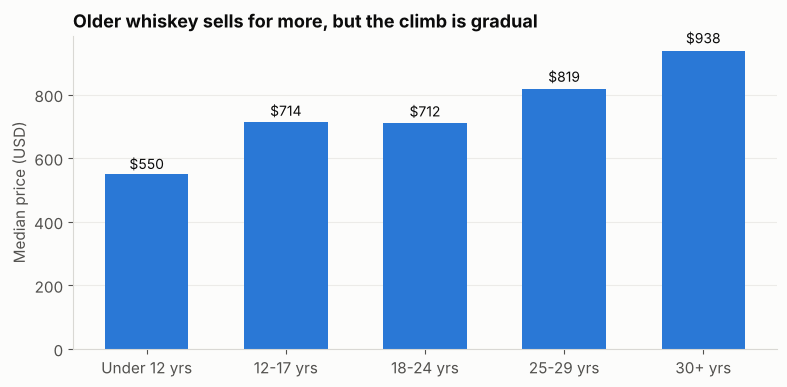

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = df["age_group"].str.split(": ").str[1]
ax.bar(labels, df["median_price"], color=BLUE, width=0.6)
for x, v in enumerate(df["median_price"]):
    ax.text(x, v * 1.02 + 5, f"${v:,.0f}", ha="center", color=INK, fontsize=10)
ax.set_title("Older whiskey sells for more, but the climb is gradual")
ax.set_ylabel("Median price (USD)"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/age_vs_price.png", dpi=150); plt.show()

**What it means:** Older whisky does sell for more. 30+ year bottles have a median of $938, about **1.7x** the under-12 group. But the climb is smaller than you might expect, and 12–17 and 18–24 year bottles are nearly identical. Young bottles are already pricey here because the auction market is mostly collector releases, so age is a real driver of value but not the only one.

## Step 4: How has the auction market grown?
**New skill: `JOIN`.** The `prices` table has individual sales, and `bottles` has the details about each bottle. A `JOIN` matches rows from the two tables using a shared ID (`prices.bottle_id = bottles.id`), like looking up each sale's bottle in a HashMap.

In [7]:
q("""
SELECT b.category,
       COUNT(*)                       AS auction_sales,
       ROUND(MEDIAN(p.price_usd), 0)  AS median_sale_price
FROM prices p
JOIN bottles b ON p.bottle_id = b.id
WHERE p.source = 'AUCTION'
GROUP BY b.category
ORDER BY auction_sales DESC
""")

,category,auction_sales,median_sale_price
0,OTHER,912450,487.0
1,BOURBON,379933,350.0
2,SCOTCH_SINGLE_MALT,24411,124.0
3,JAPANESE,3581,265.0


Now count sales by year. `year()` pulls the year out of a date.

In [8]:
q("""
SELECT year(transaction_date)        AS year,
       COUNT(*)                      AS auction_sales,
       ROUND(MEDIAN(price_usd), 0)   AS median_sale_price
FROM prices
WHERE source = 'AUCTION'
  AND year(transaction_date) BETWEEN 2010 AND 2025
GROUP BY year
ORDER BY year
""")

,year,auction_sales,median_sale_price
0,2010,1336,98.0
1,2011,1452,127.0
2,2012,1387,103.0
3,2013,1687,127.0
4,2014,35833,210.0
5,2015,59244,250.0
6,2016,22000,280.0
7,2017,31623,440.0
8,2018,23157,387.0
9,2019,17091,215.0


**Watch out:** the median price jumps around a lot, and the number of recorded sales explodes after 2022. That's because *which* bottles get recorded changes from year to year, not because prices really doubled. Comparing the yearly median would be misleading, so Step 5 measures it properly.

## Step 5: Whiskey vs. the stock market
To measure real growth, track **the same bottles** from one year to the next. That's how real-estate price indexes work: compare a house to its own earlier sale, not to other houses.

**New skills: CTEs and window functions**
- `WITH name AS (...)` (a **CTE**) builds a temporary table you can use in the next step. It's like storing an intermediate result in a variable.
- `LAG(med) OVER (PARTITION BY bottle_id ORDER BY yr)` grabs **the previous year's price for the same bottle**. `PARTITION BY` keeps each bottle separate, and `ORDER BY` puts its years in order.

**The steps in the query**
1. `yearly`: each bottle's median auction price in each year (at least 3 sales that year)
2. `changes`: divide this year's price by last year's for the same bottle (only back-to-back years)
3. Final step: the median change across all bottles for each year

In [9]:
whisky = q("""
WITH yearly AS (
    SELECT bottle_id,
           year(transaction_date)  AS yr,
           MEDIAN(price_usd)       AS med
    FROM prices
    WHERE source = 'AUCTION'
      AND year(transaction_date) BETWEEN 2013 AND 2025
    GROUP BY bottle_id, yr
    HAVING COUNT(*) >= 3
),
changes AS (
    SELECT bottle_id, yr,
           med / LAG(med) OVER (PARTITION BY bottle_id ORDER BY yr) AS ratio,
           yr  - LAG(yr)  OVER (PARTITION BY bottle_id ORDER BY yr) AS years_apart
    FROM yearly
)
SELECT yr                                AS year,
       COUNT(*)                          AS bottles_compared,
       ROUND(100 * (MEDIAN(ratio) - 1), 1) AS whisky_change_pct
FROM changes
WHERE years_apart = 1
GROUP BY yr
ORDER BY yr
""")
whisky

,year,bottles_compared,whisky_change_pct
0,2014,20,5.3
1,2015,61,0.7
2,2016,56,11.9
3,2017,56,20.3
4,2018,54,0.2
5,2019,46,-3.7
6,2020,43,13.1
7,2021,30,11.6
8,2022,31,-3.8
9,2023,67,-6.0


Same idea for the S&P 500: average index level per year, then `LAG` for the year-over-year % change.

In [10]:
stocks = q("""
WITH yearly AS (
    SELECT year(Date) AS yr, AVG(SP500) AS level
    FROM sp500
    WHERE year(Date) BETWEEN 2013 AND 2025
    GROUP BY yr
)
SELECT yr AS year,
       ROUND(100 * (level / LAG(level) OVER (ORDER BY yr) - 1), 1) AS sp500_change_pct
FROM yearly
ORDER BY yr
""")
compare = whisky.merge(stocks, on="year")
compare

,year,bottles_compared,whisky_change_pct,sp500_change_pct
0,2014,20,5.3,17.5
1,2015,61,0.7,6.8
2,2016,56,11.9,1.5
3,2017,56,20.3,17.0
4,2018,54,0.2,12.1
5,2019,46,-3.7,6.1
6,2020,43,13.1,10.5
7,2021,30,11.6,32.6
8,2022,31,-3.8,-3.9
9,2023,67,-6.0,4.7


**Python step:** turn the yearly % changes into a growth index starting at 100 in 2013. `cumprod()` multiplies the changes together year after year, the way compound interest works.

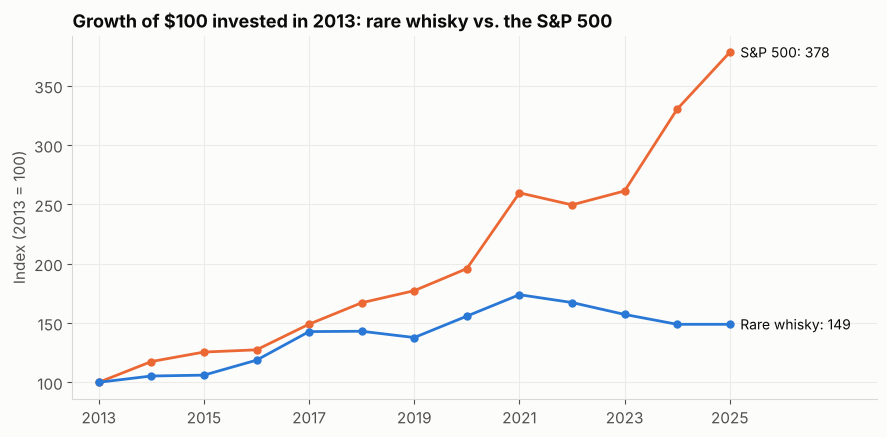

Average yearly growth, 2013-2025:  whisky 3.4%   S&P 500 11.7%


In [11]:
compare["whisky_index"] = 100 * (1 + compare["whisky_change_pct"] / 100).cumprod()
compare["sp500_index"] = 100 * (1 + compare["sp500_change_pct"] / 100).cumprod()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot([2013] + compare["year"].tolist(), [100] + compare["sp500_index"].tolist(), color=ORANGE, linewidth=2, marker="o", markersize=5)
ax.plot([2013] + compare["year"].tolist(), [100] + compare["whisky_index"].tolist(), color=BLUE, linewidth=2, marker="o", markersize=5)
last = compare.iloc[-1]
ax.text(last["year"] + 0.2, last["sp500_index"], f"S&P 500: {last['sp500_index']:.0f}", va="center", color=INK, fontsize=10)
ax.text(last["year"] + 0.2, last["whisky_index"], f"Rare whisky: {last['whisky_index']:.0f}", va="center", color=INK, fontsize=10)
ax.set_xlim(2012.5, 2027.8); ax.set_xticks(range(2013, 2026, 2))
ax.set_title("Growth of $100 invested in 2013: rare whisky vs. the S&P 500")
ax.set_ylabel("Index (2013 = 100)")
plt.tight_layout(); plt.savefig("images/whisky_vs_sp500.png", dpi=150); plt.show()

whisky_cagr = (last["whisky_index"] / 100) ** (1 / len(compare)) - 1
sp_cagr = (last["sp500_index"] / 100) ** (1 / len(compare)) - 1
print(f"Average yearly growth, 2013-2025:  whisky {whisky_cagr:.1%}   S&P 500 {sp_cagr:.1%}")

**What it means:** Rare whisky did boom, especially in 2016–2017 (+12%, +20%) and 2020–2021 (+13%, +12%). Then it fell every year from 2022 to 2024 and was flat in 2025. Over 2013–2025, whisky grew about **3.4% a year vs. 11.7% for the S&P 500**, so $100 became roughly $150 in whisky vs. about $375 in stocks.

The stock numbers don't even include dividends, and the whisky numbers don't subtract its costs: auction fees, storage, insurance, and the risk of fakes or breakage.

## Step 6: Conclusion
**Is rare whiskey a good investment?** Based on this data, **not compared to the stock market.** Whisky prices go through real booms, but they also fall, and over 2013–2025 a simple S&P 500 index fund grew more than 3x faster per year (11.7% vs. 3.4%).

What does drive value: **age** (30+ year bottles sell for ~1.7x under-12s) and **category** (the typical collectible bourbon sells for ~2.7x the typical Scotch single malt).

**Limitations**
- Only ~30–70 bottles per year have enough back-to-back sales to compare, so each year's number is a small sample.
- Some listings group several related releases, which adds noise.
- Auction prices only. No fees, storage, or retail data are included in the returns.

**Next questions to explore:** Do bourbon and Scotch behave differently as investments? Do limited releases (`is_limited_release`) hold value better?